# Member 2 — District-map verification

This notebook verifies the **existing local** San José council-district snapshot and reproduces the forecasting pipeline's district assignment for cleaned requests created in 2018–2024. It does not download a map, change coordinates, alter district assignments, run a forecasting model, or use 2025 records.

Status language used here:
- **Verified**: directly checked from local files and calculated outputs.
- **Provisional**: technically usable but still depends on a team assumption.
- **Unresolved**: cannot be established from the repository alone.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import shape
from shapely.validation import explain_validity
from IPython.display import display, Image

root = Path.cwd().resolve()
while not (root / 'src' / 'demand_forecasting.py').exists():
    if root == root.parent:
        raise RuntimeError('Run this notebook from within the project repository.')
    root = root.parent
sys.path.insert(0, str(root / 'src'))

# Reuse the exact assignment function used by the forecasting teammate.
from demand_forecasting import assign_districts

data_path = root / 'data/processed/illegal_dumping_cleaned.csv'
boundary_path = root / 'data/reference/council_districts_snapshot.geojson'
metadata_path = root / 'data/reference/council_districts_metadata.json'
audit_path = root / 'results/demand_forecasting/location_audit.csv'

print('Repository root located successfully.')
print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__, '| shapely:', shapely.__version__)

Repository root located successfully.
Python: 3.11.15
pandas: 2.3.3 | shapely: 2.0.7


## Concepts in simple English

A **polygon** is a closed map shape representing a council district. A **spatial join** asks which polygon contains each request point. For example, if a request's longitude and latitude fall inside District 3's polygon, the request receives district label 3.

A **coordinate reference system (CRS)** explains what coordinate numbers mean. The request data uses longitude followed by latitude in decimal degrees. The saved GeoJSON also looks like longitude/latitude data, but its export CRS is not explicitly stored in the GeoJSON. That missing documentation is treated as unresolved rather than silently assumed to be proven.

In [2]:
required = [data_path, boundary_path, metadata_path, audit_path]
missing_files = [str(path) for path in required if not path.exists()]
if missing_files:
    raise FileNotFoundError(f'Required local files are missing: {missing_files}')

geojson = json.loads(boundary_path.read_text(encoding='utf-8'))
metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
requests = pd.read_csv(data_path, dtype={'request_id': 'string'}, low_memory=False)
reported_audit = pd.read_csv(audit_path)

hashes = pd.Series({
    'cleaned_data_sha256': hashlib.sha256(data_path.read_bytes()).hexdigest(),
    'boundary_sha256': hashlib.sha256(boundary_path.read_bytes()).hexdigest(),
}, name='SHA-256')
display(hashes.to_frame())
print(f'Cleaned rows loaded: {len(requests):,}')

,SHA-256
cleaned_data_sha256,c075709e37fa3050f5d53c94fb9db486e169c44a13d2fd...
boundary_sha256,29ba080e546a747541716349e4c0620923a751322ea37a...


Cleaned rows loaded: 213,431


## 1. Map source, version, and geometry checks

The repository documents the source as the City of San José ArcGIS layer `PLN_AdministrativeBoundaries/MapServer/1`. Its metadata calls it **City Council Districts (Current)** and says the boundaries are the 2021 districts, effective February 11, 2022, with later updates as needed for annexations or city-boundary changes. Therefore this is a frozen local copy of a current, changing service—not an official set of historical boundaries for every request year.

In [3]:
features = geojson.get('features', [])
geometry_rows = []
for feature in features:
    district = int(feature['properties']['DISTRICT'])
    geometry = shape(feature['geometry'])
    geometry_rows.append({
        'district': district,
        'geometry_type': geometry.geom_type,
        'is_valid': geometry.is_valid,
        'is_empty': geometry.is_empty,
        'validity_detail': explain_validity(geometry),
    })
geometry_check = pd.DataFrame(geometry_rows).sort_values('district').reset_index(drop=True)
districts = geometry_check['district'].tolist()

assert geojson.get('type') == 'FeatureCollection', 'Expected a GeoJSON FeatureCollection.'
assert districts == list(range(1, 11)), f'Expected districts 1–10 exactly; found {districts}'
assert geometry_check['district'].is_unique, 'District identifiers must be unique.'
assert geometry_check['is_valid'].all(), 'At least one district geometry is invalid.'
assert not geometry_check['is_empty'].any(), 'At least one district geometry is empty.'
assert set(geometry_check['geometry_type']).issubset({'Polygon', 'MultiPolygon'})

display(geometry_check)
source_summary = pd.Series({
    'layer_name': metadata.get('name'),
    'layer_url': 'https://geo.sanjoseca.gov/server/rest/services/PLN/PLN_AdministrativeBoundaries/MapServer/1',
    'metadata_native_wkid': metadata.get('spatialReference', {}).get('wkid'),
    'metadata_latest_wkid': metadata.get('spatialReference', {}).get('latestWkid'),
    'geojson_crs_member': geojson.get('crs'),
    'feature_count': len(features),
}, name='value')
display(source_summary.to_frame())

,district,geometry_type,is_valid,is_empty,validity_detail
0,1,Polygon,True,False,Valid Geometry
1,2,MultiPolygon,True,False,Valid Geometry
2,3,Polygon,True,False,Valid Geometry
3,4,Polygon,True,False,Valid Geometry
4,5,MultiPolygon,True,False,Valid Geometry
5,6,Polygon,True,False,Valid Geometry
6,7,Polygon,True,False,Valid Geometry
7,8,Polygon,True,False,Valid Geometry
8,9,Polygon,True,False,Valid Geometry
9,10,Polygon,True,False,Valid Geometry


,value
layer_name,City Council Districts (Current)
layer_url,https://geo.sanjoseca.gov/server/rest/services...
metadata_native_wkid,102643
metadata_latest_wkid,2227
geojson_crs_member,None
feature_count,10


In [4]:
district_geometries = {
    int(feature['properties']['DISTRICT']): shape(feature['geometry'])
    for feature in features
}
all_coordinate_pairs = []
def collect_coordinate_pairs(value):
    if (isinstance(value, list) and len(value) >= 2
            and all(isinstance(item, (int, float)) for item in value[:2])):
        all_coordinate_pairs.append(value[:2])
    elif isinstance(value, list):
        for item in value:
            collect_coordinate_pairs(item)

for feature in features:
    collect_coordinate_pairs(feature['geometry']['coordinates'])
coordinate_array = np.asarray(all_coordinate_pairs)
map_bounds = pd.Series({
    'minimum_longitude': coordinate_array[:, 0].min(),
    'maximum_longitude': coordinate_array[:, 0].max(),
    'minimum_latitude': coordinate_array[:, 1].min(),
    'maximum_latitude': coordinate_array[:, 1].max(),
}, name='decimal_degrees')
display(map_bounds.to_frame())
print('PROVISIONAL CRS INTERPRETATION: coordinate ranges look like longitude/latitude,')
print('but the saved GeoJSON has no explicit CRS member or recorded export query.')

,decimal_degrees
minimum_longitude,-122.046068
maximum_longitude,-121.586150
minimum_latitude,37.122718
maximum_latitude,37.469216


PROVISIONAL CRS INTERPRETATION: coordinate ranges look like longitude/latitude,
but the saved GeoJSON has no explicit CRS member or recorded export query.


## 2. Cleaned 2018–2024 request selection

The forecasting development period ends on December 31, 2024. The cleaned file also contains 2025 records, but those are deliberately excluded here so this verification cannot inspect or influence final-test forecasting labels. Missing or non-numeric coordinates would stop the reproduction with a clear error instead of being silently altered.

In [5]:
requests['date_created'] = pd.to_datetime(requests['date_created'], errors='raise')
requests['latitude'] = pd.to_numeric(requests['latitude'], errors='coerce')
requests['longitude'] = pd.to_numeric(requests['longitude'], errors='coerce')
development = requests.loc[
    requests['date_created'].between('2018-01-01', '2024-12-31 23:59:59')
].copy()

coordinate_quality = pd.Series({
    'development_rows': len(development),
    'missing_latitude': int(development['latitude'].isna().sum()),
    'missing_longitude': int(development['longitude'].isna().sum()),
    'non_finite_coordinate_rows': int((~np.isfinite(development[['longitude', 'latitude']])).any(axis=1).sum()),
    '2025_rows_used': int((development['date_created'].dt.year == 2025).sum()),
}, name='count')
display(coordinate_quality.to_frame())
assert len(development) == 181_326
assert coordinate_quality['non_finite_coordinate_rows'] == 0
assert coordinate_quality['2025_rows_used'] == 0

,count
development_rows,181326
missing_latitude,0
missing_longitude,0
non_finite_coordinate_rows,0
2025_rows_used,0


## 3. Reproduce the teammate's spatial assignment

The reused function creates one point per request using `(longitude, latitude)` and tests it against every district polygon with `covers`. A unique match means exactly one polygon covers the point. Zero matches means the point is outside all saved polygons. More than one match can happen on a shared boundary because both polygons may cover the same boundary point; those cases are treated as ambiguous rather than arbitrarily accepted.

In [6]:
mapped = assign_districts(development, geojson)
assignment_summary = pd.Series({
    'development_requests': len(mapped),
    'uniquely_assigned': int(mapped['location_matches'].eq(1).sum()),
    'unmatched': int(mapped['location_matches'].eq(0).sum()),
    'multiple_matches': int(mapped['location_matches'].gt(1).sum()),
}, name='requests')
display(assignment_summary.to_frame())

assert assignment_summary['development_requests'] == 181_326
assert assignment_summary['uniquely_assigned'] == 180_863
assert assignment_summary['unmatched'] == 463
assert assignment_summary['multiple_matches'] == 0
assert mapped.loc[mapped['location_matches'].eq(1), 'district'].between(1, 10).all()

reproduced_audit = (mapped
    .groupby([mapped['date_created'].dt.year.rename('year'), 'location_matches'])
    .size().rename('requests').reset_index())
reported_sorted = reported_audit.sort_values(['year', 'location_matches']).reset_index(drop=True)
reproduced_sorted = reproduced_audit.sort_values(['year', 'location_matches']).reset_index(drop=True)
pd.testing.assert_frame_equal(reproduced_sorted, reported_sorted, check_dtype=False)
display(reproduced_sorted)
print('VERIFIED: recomputed annual audit exactly matches the committed forecasting audit.')

,requests
development_requests,181326
uniquely_assigned,180863
unmatched,463
multiple_matches,0


,year,location_matches,requests
0,2018,0,44
1,2018,1,22665
2,2019,0,64
3,2019,1,24425
4,2020,0,49
5,2020,1,26790
6,2021,0,85
7,2021,1,27455
8,2022,0,95
9,2022,1,22616


VERIFIED: recomputed annual audit exactly matches the committed forecasting audit.


## 4. Investigate unmatched points without changing them

An unmatched point is not automatically an error. It may be just outside the city boundary, use an imprecise location, reflect an annexation/change, or contain a source-coordinate problem that still passed the broad cleaning bounds. This notebook preserves all 463 rows and summarizes them; it does not correct, delete, or force them into a district.

Distances below are measured in **angular degrees**, not meters, because the local GeoJSON does not document its export CRS. They are useful for relative screening only.

In [7]:
unmatched = mapped.loc[mapped['location_matches'].eq(0)].copy()
unmatched_points = shapely.points(unmatched['longitude'].to_numpy(), unmatched['latitude'].to_numpy())
district_union = shapely.union_all(list(district_geometries.values()))
unmatched['distance_to_map_degrees'] = shapely.distance(unmatched_points, district_union)

distance_by_district = np.column_stack([
    shapely.distance(unmatched_points, district_geometries[district])
    for district in districts
])
unmatched['nearest_district'] = np.asarray(districts)[distance_by_district.argmin(axis=1)]
minx, miny, maxx, maxy = district_union.bounds
unmatched['inside_map_bounding_box'] = (
    unmatched['longitude'].between(minx, maxx)
    & unmatched['latitude'].between(miny, maxy)
)

unmatched_summary = pd.Series({
    'unmatched_rows': len(unmatched),
    'inside_overall_map_bounding_box': int(unmatched['inside_map_bounding_box'].sum()),
    'within_0.0001_degrees_of_map': int(unmatched['distance_to_map_degrees'].le(0.0001).sum()),
    'within_0.001_degrees_of_map': int(unmatched['distance_to_map_degrees'].le(0.001).sum()),
    'median_distance_degrees': unmatched['distance_to_map_degrees'].median(),
    'maximum_distance_degrees': unmatched['distance_to_map_degrees'].max(),
}, name='value')
display(unmatched_summary.to_frame())
display(pd.crosstab(
    unmatched['date_created'].dt.year.rename('year'),
    unmatched['nearest_district'],
    margins=True
))
display(unmatched.nsmallest(10, 'distance_to_map_degrees')[
    ['request_id', 'date_created', 'latitude', 'longitude', 'nearest_district', 'distance_to_map_degrees']
].reset_index(drop=True))

,value
unmatched_rows,463.000000
inside_overall_map_bounding_box,459.000000
within_0.0001_degrees_of_map,170.000000
within_0.001_degrees_of_map,365.000000
median_distance_degrees,0.000207
maximum_distance_degrees,0.076656


nearest_district,1,2,4,5,6,7,8,9,10,All
year,,,,,,,,,,
2018,3,5,8,1,8,2,12,4,1,44
2019,10,9,10,8,7,5,12,2,1,64
2020,3,6,6,15,7,6,5,0,1,49
2021,7,26,14,17,3,6,7,5,0,85
2022,15,17,6,15,16,18,6,1,1,95
2023,11,6,2,28,8,7,2,2,2,68
2024,5,5,4,30,8,0,4,2,0,58
All,54,74,50,114,57,44,48,16,6,463


,request_id,date_created,latitude,longitude,nearest_district,distance_to_map_degrees
0,586382,2020-08-13 14:25:05,37.294403,-121.918771,6,3.696861e-08
1,235049,2018-10-22 10:11:54,37.236165,-121.934752,9,6.144632e-08
2,974270,2022-04-17 16:12:34,37.276792,-121.804714,2,1.683872e-07
3,275074,2019-01-26 12:16:30,37.283606,-121.976657,1,2.901110e-07
4,622534,2020-11-05 12:57:55,37.282743,-121.845921,7,7.553790e-07
5,967899,2022-04-08 10:16:06,37.290747,-121.974635,1,9.231633e-07
6,679185,2021-03-17 08:01:55,37.272980,-121.744350,8,9.876332e-07
7,1631690,2024-07-25 09:16:43,37.331966,-121.771785,8,1.101977e-06
8,344502,2019-06-12 11:28:11,37.323102,-121.987336,1,1.396456e-06
9,228112,2018-10-05 13:40:41,37.354294,-121.794229,8,1.557236e-06


## 5. Boundary-related ambiguity screening

Exact multiple matches are the strongest directly observed ambiguity signal. We also count uniquely assigned points very close to any district boundary. A near-boundary point is **not proven wrong**; it is simply more sensitive to coordinate rounding or a different boundary vintage.

In [8]:
unique = mapped.loc[mapped['location_matches'].eq(1)].copy()
unique_points = shapely.points(unique['longitude'].to_numpy(), unique['latitude'].to_numpy())
boundary_distances = np.column_stack([
    shapely.distance(unique_points, district_geometries[district].boundary)
    for district in districts
])
unique['minimum_boundary_distance_degrees'] = boundary_distances.min(axis=1)
boundary_screen = pd.Series({
    'exact_multiple_matches': int(mapped['location_matches'].gt(1).sum()),
    'unique_points_on_a_boundary_at_numeric_precision': int(np.isclose(unique['minimum_boundary_distance_degrees'], 0.0, atol=1e-12).sum()),
    'unique_points_within_0.00001_degrees': int(unique['minimum_boundary_distance_degrees'].le(0.00001).sum()),
    'unique_points_within_0.0001_degrees': int(unique['minimum_boundary_distance_degrees'].le(0.0001).sum()),
}, name='requests')
display(boundary_screen.to_frame())
print('Interpretation: proximity is a sensitivity flag, not evidence that an assignment is incorrect.')

,requests
exact_multiple_matches,0
unique_points_on_a_boundary_at_numeric_precision,0
unique_points_within_0.00001_degrees,909
unique_points_within_0.0001_degrees,4120


Interpretation: proximity is a sensitivity flag, not evidence that an assignment is incorrect.


## 6. District map with a reproducible request sample

Plotting all 180,863 matched points would hide the district outlines. The chart therefore uses a deterministic sample of up to 40 uniquely assigned requests per district and overlays all unmatched points. The sample affects only the picture, not any verification count.

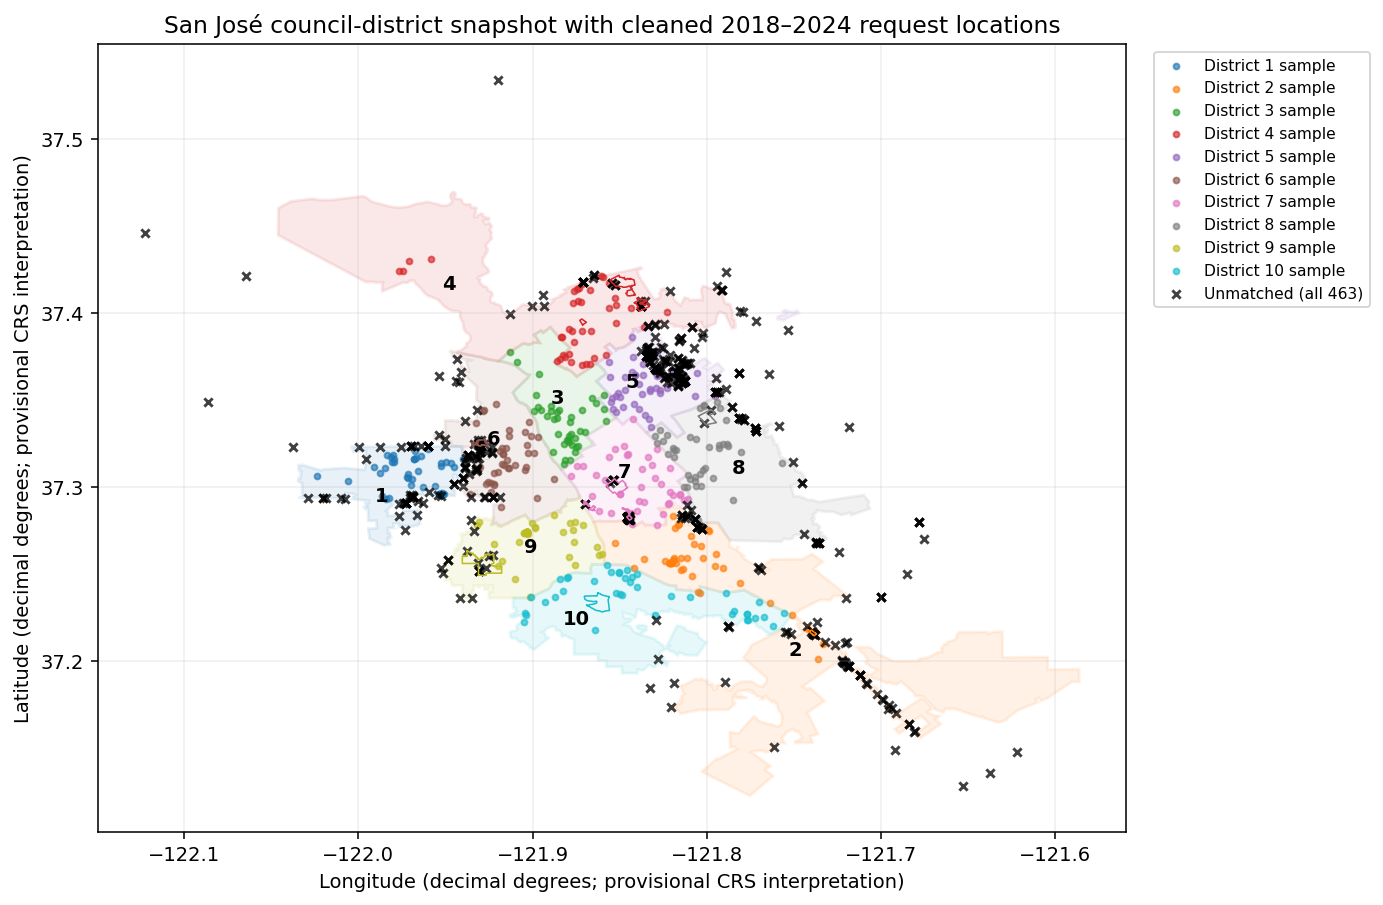

In [9]:
sampled_parts = []
for district, group in unique.groupby('district'):
    sampled_parts.append(group.sample(n=min(40, len(group)), random_state=245))
sampled = pd.concat(sampled_parts, ignore_index=True)
colors = plt.get_cmap('tab10')
fig, ax = plt.subplots(figsize=(10, 10))

for district in districts:
    geometry = district_geometries[district]
    parts = list(geometry.geoms) if geometry.geom_type == 'MultiPolygon' else [geometry]
    color = colors((district - 1) % 10)
    for part in parts:
        x, y = part.exterior.xy
        ax.fill(x, y, facecolor=color, alpha=0.10, edgecolor=color, linewidth=1.5)
        for interior in part.interiors:
            hx, hy = interior.xy
            ax.plot(hx, hy, color=color, linewidth=0.8)
    district_sample = sampled.loc[sampled['district'].eq(district)]
    ax.scatter(district_sample['longitude'], district_sample['latitude'], s=9,
               color=color, alpha=0.65, label=f'District {district} sample')
    label_point = geometry.representative_point()
    ax.text(label_point.x, label_point.y, str(district), ha='center', va='center',
            fontsize=10, fontweight='bold', color='black')

ax.scatter(unmatched['longitude'], unmatched['latitude'], s=18, marker='x',
           color='black', alpha=0.75, label=f'Unmatched (all {len(unmatched)})')
ax.set_title('San José council-district snapshot with cleaned 2018–2024 request locations')
ax.set_xlabel('Longitude (decimal degrees; provisional CRS interpretation)')
ax.set_ylabel('Latitude (decimal degrees; provisional CRS interpretation)')
ax.set_aspect('equal', adjustable='box')
ax.grid(alpha=0.2)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=140, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(fig)

## 7. Conclusions and limitations

### Verified
- The saved map has exactly one feature for every district from 1 through 10.
- All features are non-empty valid Polygon or MultiPolygon geometries.
- Reusing the forecasting assignment on actual cleaned 2018–2024 records reproduces 181,326 requests, 180,863 unique matches, 463 unmatched requests, and zero multiple matches.
- The recomputed year-by-year audit exactly matches the committed forecasting audit.
- No 2025 records were used.

### Provisional
- Longitude/latitude order is consistent between requests, the saved coordinate ranges, and the forecasting function.
- The local snapshot can provide one consistent retrospective geography if the team explicitly chooses that study design.

### Unresolved
- The saved GeoJSON does not record its export query, acquisition time, or explicit export CRS.
- This current 2021-boundary layer cannot establish historically correct council districts for requests before February 11, 2022, or fully account for later annexation updates.
- The repository does not contain independent known-address checks or official historical district layers.
- Unmatched and near-boundary points need team review; this notebook intentionally does not repair or reassign them.